# Respaldo del informe descriptivo de admisiones

Instituto Universitario Horizonte. Primera exploración de las 5.040 filas originales.

Este cuaderno reproduce el reconocimiento, el diagnóstico de calidad, las frecuencias, los porcentajes,
las estadísticas numéricas y las figuras utilizadas en el informe. No modifica el CSV ni necesita Docker.
Los duplicados y las variantes de escritura permanecen en la base de cálculo.

Las hipótesis finales se distinguen de los hechos observados. Las equivalencias de presentación
se examinan en un apartado separado y no sustituyen las distribuciones originales.

## Cómo leerlo

Recorrer las secciones en orden. Cada apartado contiene una explicación, el cálculo y su salida.
Las verificaciones finales contrastan las cifras citadas en el informe y comprueban la integridad del origen.
Las fuentes teóricas locales son Calidad de datos, especialmente diapositivas 6 a 16, y la guía del caso.


In [1]:
from pathlib import Path
import collections
import csv
from datetime import datetime, date
import hashlib
import json
import re
import sys
import os

os.environ.setdefault('MPLCONFIGDIR', '/tmp/admisiones-matplotlib')
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
from analitica_admisiones.profiling import read_original, numeric_summary

meta = json.loads((ROOT / 'docker/origen.json').read_text(encoding='utf-8'))
source = ROOT / meta['archivo']
original_bytes = source.read_bytes()
original_hash = hashlib.sha256(original_bytes).hexdigest()
assert original_hash == meta['sha256'], 'El CSV difiere del origen registrado'
headers, rows = read_original(source)
df = pd.DataFrame(rows, columns=headers)
original_df = df.copy(deep=True)
N = len(df)
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_colwidth', 95)
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)
print('Origen:', source.relative_to(ROOT))
print('SHA256:', original_hash)


Python: 3.12.3 | pandas: 3.0.6
Origen: data/raw/Caso2_Admisiones_Universitarias.csv
SHA256: 0d4c756649ccff9dcf5c2c2cc5edba0ced8f8e3c157ee2c1f5b4bd2939b8f467


## 1. Reconocimiento del conjunto

Una fila representa un registro del archivo. No se presupone que sea una solicitud única,
un aspirante único o una matrícula efectiva. Todos los valores se leen como texto y los vacíos
se conservan como cadenas vacías. La naturaleza analítica esperada se muestra por separado.


In [2]:
expected = {
    'registro_id': 'Identificador', 'aspirante_id': 'Identificador',
    'fecha_solicitud': 'Fecha', 'programa': 'Categórica', 'modalidad': 'Categórica',
    'canal_captacion': 'Categórica', 'estado_proceso': 'Categórica',
    'puntaje_admision': 'Numérica', 'documentos_completos': 'Categórica',
    'valor_matricula_cop': 'Numérica en COP', 'ciudad_residencia': 'Categórica',
    'asesor': 'Categórica', 'fecha_matricula': 'Fecha', 'correo': 'Texto de contacto',
    'periodo_academico': 'Categórica temporal',
}
display(pd.DataFrame([{
    'Filas': N, 'Columnas': len(df.columns),
    'registro_id distintos': df.registro_id.nunique(),
    'aspirante_id distintos no vacíos': df.loc[df.aspirante_id.ne(''), 'aspirante_id'].nunique(),
    'aspirante_id vacíos': df.aspirante_id.eq('').sum(),
}]))
display(pd.DataFrame({'Columna': headers, 'Naturaleza esperada': [expected[c] for c in headers],
                      'Lectura original': 'Texto conservado'}))


,Filas,Columnas,registro_id distintos,aspirante_id distintos no vacíos,aspirante_id vacíos
0,5040,15,5000,2924,92


,Columna,Naturaleza esperada,Lectura original
0,registro_id,Identificador,Texto conservado
1,aspirante_id,Identificador,Texto conservado
2,fecha_solicitud,Fecha,Texto conservado
3,programa,Categórica,Texto conservado
4,modalidad,Categórica,Texto conservado
5,canal_captacion,Categórica,Texto conservado
6,estado_proceso,Categórica,Texto conservado
7,puntaje_admision,Numérica,Texto conservado
8,documentos_completos,Categórica,Texto conservado
9,valor_matricula_cop,Numérica en COP,Texto conservado


## 2. Diagnóstico inicial de calidad

Se separan vacíos exactos, valores con solo espacios y estados explícitos como Pendiente,
No aplica o por definir. La obligatoriedad depende del contexto. No se rellenan ausencias con cero.


In [3]:
quality = pd.DataFrame([{
    'Columna': c,
    'Vacíos exactos': int(df[c].eq('').sum()),
    'Solo espacios': int((df[c].ne('') & df[c].str.strip().eq('')).sum()),
    'Porcentaje vacío exacto': round(100 * df[c].eq('').sum() / N, 2),
    'Categorías distintas incluyendo vacíos': df[c].nunique(),
} for c in headers])
display(quality)


,Columna,Vacíos exactos,Solo espacios,Porcentaje vacío exacto,Categorías distintas incluyendo vacíos
0,registro_id,0,0,0.00,5000
1,aspirante_id,92,0,1.83,2925
2,fecha_solicitud,0,0,0.00,1226
3,programa,0,25,0.00,10
4,modalidad,0,0,0.00,5
5,canal_captacion,0,0,0.00,6
6,estado_proceso,0,0,0.00,9
7,puntaje_admision,179,0,3.55,63
8,documentos_completos,0,0,0.00,5
9,valor_matricula_cop,826,0,16.39,7


### Repeticiones exactas y diferencias de clave

Un duplicado exacto coincide en las 15 columnas. Las filas involucradas y las repeticiones
adicionales son indicadores distintos. Se muestran todos los códigos exactos y los pares parciales.
No se elimina ninguna fila de la base analizada.


In [4]:
exact_involved = df.duplicated(keep=False)
exact_extra = int(df.duplicated(keep='first').sum())
exact_codes = (df.loc[exact_involved].groupby('registro_id', sort=True).size()
               .rename('Apariciones idénticas').reset_index())
positions = collections.defaultdict(list)
for i, row in enumerate(rows, 2):
    positions[tuple(row)].append(i)
exact_details = pd.DataFrame([{
    'registro_id': values[headers.index('registro_id')],
    'Posiciones en CSV con encabezado': locs, 'Apariciones': len(locs),
} for values, locs in positions.items() if len(locs) > 1]).sort_values('registro_id')
print('Grupos exactos:', len(exact_details), '| Filas involucradas:', int(exact_involved.sum()),
      '| Repeticiones adicionales:', exact_extra)
display(exact_details)
partial_records = []
for rid, group in df.groupby('registro_id', sort=True):
    if len(group) > 1 and len({tuple(row) for row in group.to_numpy()}) > 1:
        for col in headers:
            if group[col].nunique() > 1:
                for idx, value in group[col].items():
                    partial_records.append({'registro_id': rid, 'Posición en CSV': idx + 2,
                                            'Columna diferente': col, 'Valor original visible': json.dumps(value, ensure_ascii=False)})
partial_details = pd.DataFrame(partial_records)
display(partial_details)


Grupos exactos: 38 | Filas involucradas: 76 | Repeticiones adicionales: 38


,registro_id,Posiciones en CSV con encabezado,Apariciones
23,REG000019,"[2075, 2872]",2
24,REG000020,"[2175, 2656]",2
8,REG000039,"[706, 4163]",2
14,REG000167,"[1074, 1884]",2
3,REG000363,"[401, 4436]",2
32,REG000388,"[3073, 5026]",2
37,REG000572,"[4159, 4575]",2
6,REG000581,"[526, 4435]",2
2,REG001072,"[350, 4086]",2
18,REG001077,"[1249, 5017]",2


,registro_id,Posición en CSV,Columna diferente,Valor original visible
0,REG003600,1612,valor_matricula_cop,"""por definir"""
1,REG003600,2214,valor_matricula_cop,"""1800000.0"""
2,REG004804,68,programa,""" """
3,REG004804,3167,programa,"""Ingeniería de Sistemas"""


### Repeticiones de aspirantes y solicitudes potenciales

La clave propuesta aspirante, programa y periodo no constituye una regla institucional confirmada.
Se excluyen los identificadores vacíos de este control de personas. No se homologan las categorías.


In [5]:
identified = df.loc[df.aspirante_id.ne('')]
key_counts = identified.groupby(['aspirante_id','programa','periodo_academico'], dropna=False).size()
repeated_keys = key_counts[key_counts > 1]
display(pd.DataFrame([{
    'Grupos repetidos con ID no vacío': len(repeated_keys),
    'Filas involucradas': int(repeated_keys.sum()),
    'Repeticiones adicionales': int((repeated_keys - 1).sum()),
}]))
print('Estas repeticiones no son duplicados inválidos confirmados.')


,Grupos repetidos con ID no vacío,Filas involucradas,Repeticiones adicionales
0,105,212,107


Estas repeticiones no son duplicados inválidos confirmados.


### Formatos y fechas

Se interpreta una copia temporal de cada valor mediante cinco patrones explícitos. El patrón de barras
con año al final se interpreta como día, mes y año; el patrón de guiones con año al final como mes,
día y año. Las abreviaturas de mes se interpretan en inglés. Estas convenciones deben confirmarse
con la fuente si existe ambigüedad. Las fechas derivadas no reemplazan las originales.


In [6]:
patterns = [
    ('Año mes día con guiones', r'\d{4}-\d{2}-\d{2}', '%Y-%m-%d'),
    ('Año mes día con barras', r'\d{4}/\d{2}/\d{2}', '%Y/%m/%d'),
    ('Día mes año con barras', r'\d{2}/\d{2}/\d{4}', '%d/%m/%Y'),
    ('Mes día año con guiones', r'\d{2}-\d{2}-\d{4}', '%m-%d-%Y'),
    ('Día mes abreviado año', r'\d{2}-[A-Za-z]{3}-\d{4}', '%d-%b-%Y'),
]
def parse_date(value):
    if value == '': return None, 'Vacío exacto'
    if value == 'No aplica': return None, 'No aplica'
    for label, regex, fmt in patterns:
        if re.fullmatch(regex, value):
            try: return datetime.strptime(value, fmt).date(), label
            except ValueError: return None, 'Fecha no válida bajo el patrón'
    return None, 'Formato no reconocido'

dates = {}
format_tables = {}
for column in ['fecha_solicitud','fecha_matricula']:
    parsed = [parse_date(v) for v in df[column]]
    dates[column] = pd.Series([v[0] for v in parsed], index=df.index)
    counts = pd.Series([v[1] for v in parsed]).value_counts()
    table = counts.rename_axis('Formato o condición').reset_index(name='Cantidad')
    table['Porcentaje del total'] = (100 * table['Cantidad'] / N).round(2)
    format_tables[column] = table
    display(Markdown('**' + column + '**'))
    display(table)
    available = dates[column].dropna()
    print('Fechas disponibles:', len(available), '| Mínima:', min(available), '| Máxima:', max(available))
request_2026 = dates['fecha_solicitud'].map(lambda value: value is not None and value.year == 2026)
period_mismatch = df.periodo_academico.eq('2025-2') & request_2026
print('Periodo segundo semestre de 2025 con solicitud de 2026:', int(period_mismatch.sum()))
display(df.loc[period_mismatch, ['registro_id','fecha_solicitud','periodo_academico']].head(10))
reference_date = date(2026, 10, 17)
future = dates['fecha_matricula'].map(lambda value: value is not None and value > reference_date)
print('Fechas de matrícula posteriores al 17 de octubre de 2026:', int(future.sum()))
print('La referencia anterior no es un corte institucional confirmado; pueden ser fechas programadas.')
chronology = pd.Series([m is not None and s is not None and m < s
                       for s,m in zip(dates['fecha_solicitud'], dates['fecha_matricula'])], index=df.index)
print('Matrículas anteriores a solicitud bajo las convenciones declaradas:', int(chronology.sum()))


**fecha_solicitud**

,Formato o condición,Cantidad,Porcentaje del total
0,Año mes día con guiones,4317,85.65
1,Día mes año con barras,206,4.09
2,Mes día año con guiones,182,3.61
3,Día mes abreviado año,175,3.47
4,Año mes día con barras,160,3.17


Fechas disponibles: 5040 | Mínima: 2025-01-01 | Máxima: 2026-09-12


**fecha_matricula**

,Formato o condición,Cantidad,Porcentaje del total
0,Vacío exacto,2612,51.83
1,No aplica,1343,26.65
2,Año mes día con guiones,756,15.00
3,Mes día año con guiones,89,1.77
4,Año mes día con barras,84,1.67
5,Día mes abreviado año,83,1.65
6,Día mes año con barras,73,1.45


Fechas disponibles: 1085 | Mínima: 2025-01-13 | Máxima: 2026-10-31
Periodo segundo semestre de 2025 con solicitud de 2026: 410


,registro_id,fecha_solicitud,periodo_academico
1,REG002946,2026-07-22,2025-2
7,REG003989,2026-04-10,2025-2
19,REG001559,2026-03-20,2025-2
56,REG004890,2026-08-30,2025-2
59,REG001859,2026-07-08,2025-2
64,REG004177,2026-07-22,2025-2
69,REG000988,21/02/2026,2025-2
86,REG004516,2026-07-05,2025-2
91,REG000445,2026-02-14,2025-2
92,REG000575,2026-08-09,2025-2


Fechas de matrícula posteriores al 17 de octubre de 2026: 7
La referencia anterior no es un corte institucional confirmado; pueden ser fechas programadas.
Matrículas anteriores a solicitud bajo las convenciones declaradas: 0


### Controles de formato propuestos

Los patrones siguientes son controles exploratorios, no reglas institucionales. La estructura del correo
no certifica que una dirección exista, pertenezca a la persona o pueda recibir mensajes.


In [7]:
format_controls = []
for column, regex in [('registro_id',r'REG\d{6}'),('aspirante_id',r'A\d{6}'),
                      ('correo',r'[^\s@]+@[^\s@]+\.[^\s@]+')]:
    nonempty = df[column].ne('')
    matches = df[column].str.fullmatch(regex)
    flagged = nonempty & ~matches
    format_controls.append({'Columna':column,'No vacíos revisados':int(nonempty.sum()),
                            'Fuera del patrón propuesto':int(flagged.sum())})
    if flagged.any():
        print(column, ': revisar', int(flagged.sum()), 'casos. Los correos se omiten para no exponer datos de contacto.')
display(pd.DataFrame(format_controls))


,Columna,No vacíos revisados,Fuera del patrón propuesto
0,registro_id,5040,0
1,aspirante_id,4948,0
2,correo,4920,0


## 3. Frecuencias y porcentajes originales

Cada tabla utiliza las 5.040 filas como denominador, incluidos duplicados. La representación JSON
hace visibles espacios y cadenas vacías. No se fusionan nombres, mayúsculas ni acentos.
Las frecuencias bajas o las variantes no se consideran errores automáticamente.


In [8]:
categorical = ['programa','modalidad','canal_captacion','estado_proceso',
               'documentos_completos','ciudad_residencia','asesor','periodo_academico']
frequencies = {}
for column in categorical:
    counts = df[column].value_counts(dropna=False)
    table = counts.rename_axis('Valor original').reset_index(name='Cantidad')
    table['Valor visible'] = table['Valor original'].map(lambda x: json.dumps(x, ensure_ascii=False))
    table['Porcentaje del total'] = (100 * table['Cantidad'] / N).round(2)
    frequencies[column] = table
    display(Markdown('**' + column + '**'))
    display(table)


**programa**

,Valor original,Cantidad,Valor visible,Porcentaje del total
0,Especialización en Data Analytics,576,"""Especialización en Data Analytics""",11.43
1,Ingeniería de Sistemas,572,"""Ingeniería de Sistemas""",11.35
2,DERECHO,569,"""DERECHO""",11.29
3,Especializacion en Data Analytics,560,"""Especializacion en Data Analytics""",11.11
4,Contaduría Pública,558,"""Contaduría Pública""",11.07
5,Especialización en Gerencia,554,"""Especialización en Gerencia""",10.99
6,Derecho,553,"""Derecho""",10.97
7,Psicología,549,"""Psicología""",10.89
8,Administración de Empresas,524,"""Administración de Empresas""",10.40
9,,25,""" """,0.50


**modalidad**

,Valor original,Cantidad,Valor visible,Porcentaje del total
0,Híbrida,1049,"""Híbrida""",20.81
1,Presencial,1011,"""Presencial""",20.06
2,VIRTUAL,1001,"""VIRTUAL""",19.86
3,Virtual,996,"""Virtual""",19.76
4,presencial,983,"""presencial""",19.50


**canal_captacion**

,Valor original,Cantidad,Valor visible,Porcentaje del total
0,Feria universitaria,861,"""Feria universitaria""",17.08
1,Instagram,859,"""Instagram""",17.04
2,Correo,847,"""Correo""",16.81
3,Referido,829,"""Referido""",16.45
4,Landing page,828,"""Landing page""",16.43
5,Web institucional,816,"""Web institucional""",16.19


... (6 outputs left out)

**asesor**

,Valor original,Cantidad,Valor visible,Porcentaje del total
0,Asesor 1,1028,"""Asesor 1""",20.40
1,asesor 1,1009,"""asesor 1""",20.02
2,Sin asignar,1009,"""Sin asignar""",20.02
3,Asesor 2,998,"""Asesor 2""",19.80
4,Asesor 3,996,"""Asesor 3""",19.76


**periodo_academico**

,Valor original,Cantidad,Valor visible,Porcentaje del total
0,2026 II,1042,"""2026 II""",20.67
1,2026-1,1028,"""2026-1""",20.40
2,2026-I,1005,"""2026-I""",19.94
3,2026-2,984,"""2026-2""",19.52
4,2025-2,981,"""2025-2""",19.46


## 4. Estadísticas numéricas y valores atípicos

Se conservan los valores originales. La interpretación numérica se usa únicamente para calcular
mínimo, máximo, promedio, mediana y cuartiles. Los vacíos y textos no se convierten en cero.
La regla de atípicos es Q1 menos 1,5 veces RIC y Q3 más 1,5 veces RIC, con cuartiles por
interpolación lineal. Un valor fuera del intervalo sería una alerta, no un error confirmado;
no encontrar atípicos tampoco acredita exactitud o validez de negocio.


In [9]:
numeric_records, numbers = [], {}
for column in ['puntaje_admision','valor_matricula_cop']:
    summary = numeric_summary(df[column].tolist())
    interpreted = pd.to_numeric(df[column], errors='coerce')
    valid = interpreted.notna() & np.isfinite(interpreted)
    arr = interpreted[valid].to_numpy(dtype=float)
    numbers[column] = pd.Series(arr)
    q1,q3 = np.quantile(arr,[.25,.75],method='linear')
    low,high = q1-1.5*(q3-q1), q3+1.5*(q3-q1)
    numeric_records.append({
        'Columna':column,'Valores utilizados':len(arr),'Vacíos':summary['vacios'],
        'Texto no interpretable':summary['no_interpretables'],
        'Mínimo':summary['minimo'],'Máximo':summary['maximo'],
        'Promedio':float(summary['promedio']),'Mediana':summary['mediana'],
        'Negativos':int((arr<0).sum()),'Q1':q1,'Q3':q3,
        'Límite inferior exploratorio':low,'Límite superior exploratorio':high,
        'Atípicos según criterio':int(((arr<low)|(arr>high)).sum()),
    })
numeric_table = pd.DataFrame(numeric_records)
display(numeric_table.T)
print('Los importes registrados no demuestran pago efectivo ni ingreso recibido.')


,0,1
Columna,puntaje_admision,valor_matricula_cop
Valores utilizados,4811,4179
Vacíos,179,826
Texto no interpretable,{'Pendiente': 50},{'por definir': 35}
Mínimo,40.0,1800000.0
Máximo,100.0,3500000.0
Promedio,70.055498,2611605.647284
Mediana,70.0,2500000.0
Negativos,0,0
Q1,55.0,2200000.0


Los importes registrados no demuestran pago efectivo ni ingreso recibido.


## 5. Comparaciones entre grupos

Los cruces siguientes conservan las etiquetas originales. Los conteos no representan tasas de
conversión definitivas. Los porcentajes por fila se denominan distribución del estado dentro del canal.
Se separan de los porcentajes calculados sobre todas las filas.


In [10]:
channel_state = pd.crosstab(df.canal_captacion, df.estado_proceso)
channel_state_pct = channel_state.div(channel_state.sum(axis=1),axis=0).mul(100).round(2)
display(Markdown('**Canal y estado: cantidades**'))
display(channel_state)
display(Markdown('**Canal y estado: porcentajes dentro de cada canal**'))
display(channel_state_pct)
display(Markdown('**Modalidad y estado: cantidades**'))
display(pd.crosstab(df.modalidad, df.estado_proceso))
display(Markdown('**Programa y modalidad: cantidades**'))
display(pd.crosstab(df.programa, df.modalidad))
display(Markdown('**Estado y documentación: cantidades**'))
display(pd.crosstab(df.estado_proceso, df.documentos_completos))


**Canal y estado: cantidades**

estado_proceso,ADMITIDO,Admitido,Documentación pendiente,Inscrito,Matriculado,No admitido,Nuevo,Retirado,matriculado
canal_captacion,,,,,,,,,
Correo,91,95,95,119,76,72,96,88,115
Feria universitaria,83,116,95,93,89,102,107,88,88
Instagram,77,92,103,94,113,105,76,101,98
Landing page,98,103,81,91,82,84,93,109,87
Referido,77,96,109,91,76,101,89,100,90
Web institucional,87,100,93,90,84,88,104,83,87


**Canal y estado: porcentajes dentro de cada canal**

estado_proceso,ADMITIDO,Admitido,Documentación pendiente,Inscrito,Matriculado,No admitido,Nuevo,Retirado,matriculado
canal_captacion,,,,,,,,,
Correo,10.74,11.22,11.22,14.05,8.97,8.50,11.33,10.39,13.58
Feria universitaria,9.64,13.47,11.03,10.80,10.34,11.85,12.43,10.22,10.22
Instagram,8.96,10.71,11.99,10.94,13.15,12.22,8.85,11.76,11.41
Landing page,11.84,12.44,9.78,10.99,9.90,10.14,11.23,13.16,10.51
Referido,9.29,11.58,13.15,10.98,9.17,12.18,10.74,12.06,10.86
Web institucional,10.66,12.25,11.40,11.03,10.29,10.78,12.75,10.17,10.66


**Modalidad y estado: cantidades**

estado_proceso,ADMITIDO,Admitido,Documentación pendiente,Inscrito,Matriculado,No admitido,Nuevo,Retirado,matriculado
modalidad,,,,,,,,,
Híbrida,107,131,122,120,106,105,110,118,130
Presencial,108,118,107,115,105,122,121,108,107
VIRTUAL,100,124,112,117,113,118,94,105,118
Virtual,100,120,125,107,112,99,111,118,104
presencial,98,109,110,119,84,108,129,120,106


**Programa y modalidad: cantidades**

modalidad,Híbrida,Presencial,VIRTUAL,Virtual,presencial
programa,,,,,
,3,5,4,6,7
Administración de Empresas,106,103,99,118,98
Contaduría Pública,115,111,111,111,110
DERECHO,121,111,109,111,117
Derecho,109,110,120,115,99
Especializacion en Data Analytics,110,126,119,95,110
Especialización en Data Analytics,127,110,105,106,128
Especialización en Gerencia,127,111,103,114,99
Ingeniería de Sistemas,117,120,118,99,118


**Estado y documentación: cantidades**

documentos_completos,No,Pendiente,SI,Sí,sí
estado_proceso,,,,,
ADMITIDO,90,115,85,101,122
Admitido,112,129,116,124,121
Documentación pendiente,115,105,110,133,113
Inscrito,115,109,118,109,127
Matriculado,111,114,91,112,92
No admitido,117,98,121,114,102
Nuevo,111,117,120,112,105
Retirado,105,114,132,104,114
matriculado,123,117,105,117,103


### Lecturas conjuntas explícitas

Solo para contrastar las afirmaciones que suman ambas etiquetas de matriculado, se seleccionan
Matriculado y matriculado sin modificar la columna. La suma no acredita matrícula efectiva.
La comparación por canal usa registros, no aspirantes únicos, y no mide causalidad.


In [11]:
matriculated = df.estado_proceso.isin(['Matriculado','matriculado'])
without_docs = df.documentos_completos.isin(['No','Pendiente'])
print('Registros con ambas etiquetas de matriculado:', int(matriculated.sum()))
print('Con documentación No o Pendiente:', int((matriculated & without_docs).sum()))
print('Porcentaje dentro de los registros matriculados:', round(100*(matriculated & without_docs).sum()/matriculated.sum(),2))
channel_comparison = df.groupby('canal_captacion').size().rename('Registros').to_frame()
channel_comparison['Registros con ambas etiquetas de matriculado'] = df.loc[matriculated].groupby('canal_captacion').size()
channel_comparison['Proporción preliminar sobre registros del canal'] = (
    100*channel_comparison['Registros con ambas etiquetas de matriculado']/channel_comparison['Registros']).round(2)
display(channel_comparison)
print('Documentación No o Pendiente en todo el conjunto:', int(without_docs.sum()), round(100*without_docs.mean(),2))
print('Estado Retirado:', int(df.estado_proceso.eq('Retirado').sum()), round(100*df.estado_proceso.eq('Retirado').mean(),2))
print('Asesor Sin asignar:', int(df.asesor.eq('Sin asignar').sum()), round(100*df.asesor.eq('Sin asignar').mean(),2))
display(pd.crosstab(df.asesor,df.estado_proceso))
print('Los estados no constituyen un historial. No puede calcularse permanencia en documentación pendiente con esta base.')


Registros con ambas etiquetas de matriculado: 1085
Con documentación No o Pendiente: 465
Porcentaje dentro de los registros matriculados: 42.86


,Registros,Registros con ambas etiquetas de matriculado,Proporción preliminar sobre registros del canal
canal_captacion,,,
Correo,847,191,22.55
Feria universitaria,861,177,20.56
Instagram,859,211,24.56
Landing page,828,169,20.41
Referido,829,166,20.02
Web institucional,816,171,20.96


Documentación No o Pendiente en todo el conjunto: 2017 40.02
Estado Retirado: 569 11.29
Asesor Sin asignar: 1009 20.02


estado_proceso,ADMITIDO,Admitido,Documentación pendiente,Inscrito,Matriculado,No admitido,Nuevo,Retirado,matriculado
asesor,,,,,,,,,
Asesor 1,99,100,123,124,114,109,114,128,117
Asesor 2,108,115,125,104,89,112,105,126,114
Asesor 3,101,121,97,107,104,105,130,104,127
Sin asignar,103,119,117,120,110,105,112,111,112
asesor 1,102,147,114,123,103,121,104,100,95


Los estados no constituyen un historial. No puede calcularse permanencia en documentación pendiente con esta base.


### Cobertura temporal

Las agrupaciones mensuales se calculan a partir de las fechas interpretadas. La disponibilidad
hasta el día 12 de septiembre de 2026 no demuestra que todos los meses anteriores estén completos.
No se evalúa oportunidad de actualización sin fecha de extracción y reglas de disponibilidad.


In [12]:
monthly = dates['fecha_solicitud'].map(lambda value: value.strftime('%Y/%m')).value_counts().sort_index()
display(monthly.rename_axis('Mes de solicitud').reset_index(name='Registros'))
print('Mínima solicitud:', min(dates['fecha_solicitud']))
print('Máxima solicitud:', max(dates['fecha_solicitud']))
print('Septiembre de 2026:', monthly.loc['2026/09'])


,Mes de solicitud,Registros
0,2025/01,262
1,2025/02,238
2,2025/03,234
3,2025/04,240
4,2025/05,234
5,2025/06,253
6,2025/07,245
7,2025/08,261
8,2025/09,224
9,2025/10,259


Mínima solicitud: 2025-01-01
Máxima solicitud: 2026-09-12
Septiembre de 2026: 75


## 6. Figuras del informe

Las figuras se regeneran desde los scripts del proyecto con el CSV verificado y se incrustan
como imágenes en las salidas del cuaderno. Las dos primeras conservan las variantes originales.
Los diagramas de caja y los histogramas describen distribución, no una evolución temporal.


6 figuras generadas en PNG y PDF. Original intacto. Destino: /mnt/c/Users/jdlos/Desktop/analitica_admisiones_universitaria/reports/figuras


**La fragmentación por escritura impide concluir un ranking definitivo sin validar equivalencias.**

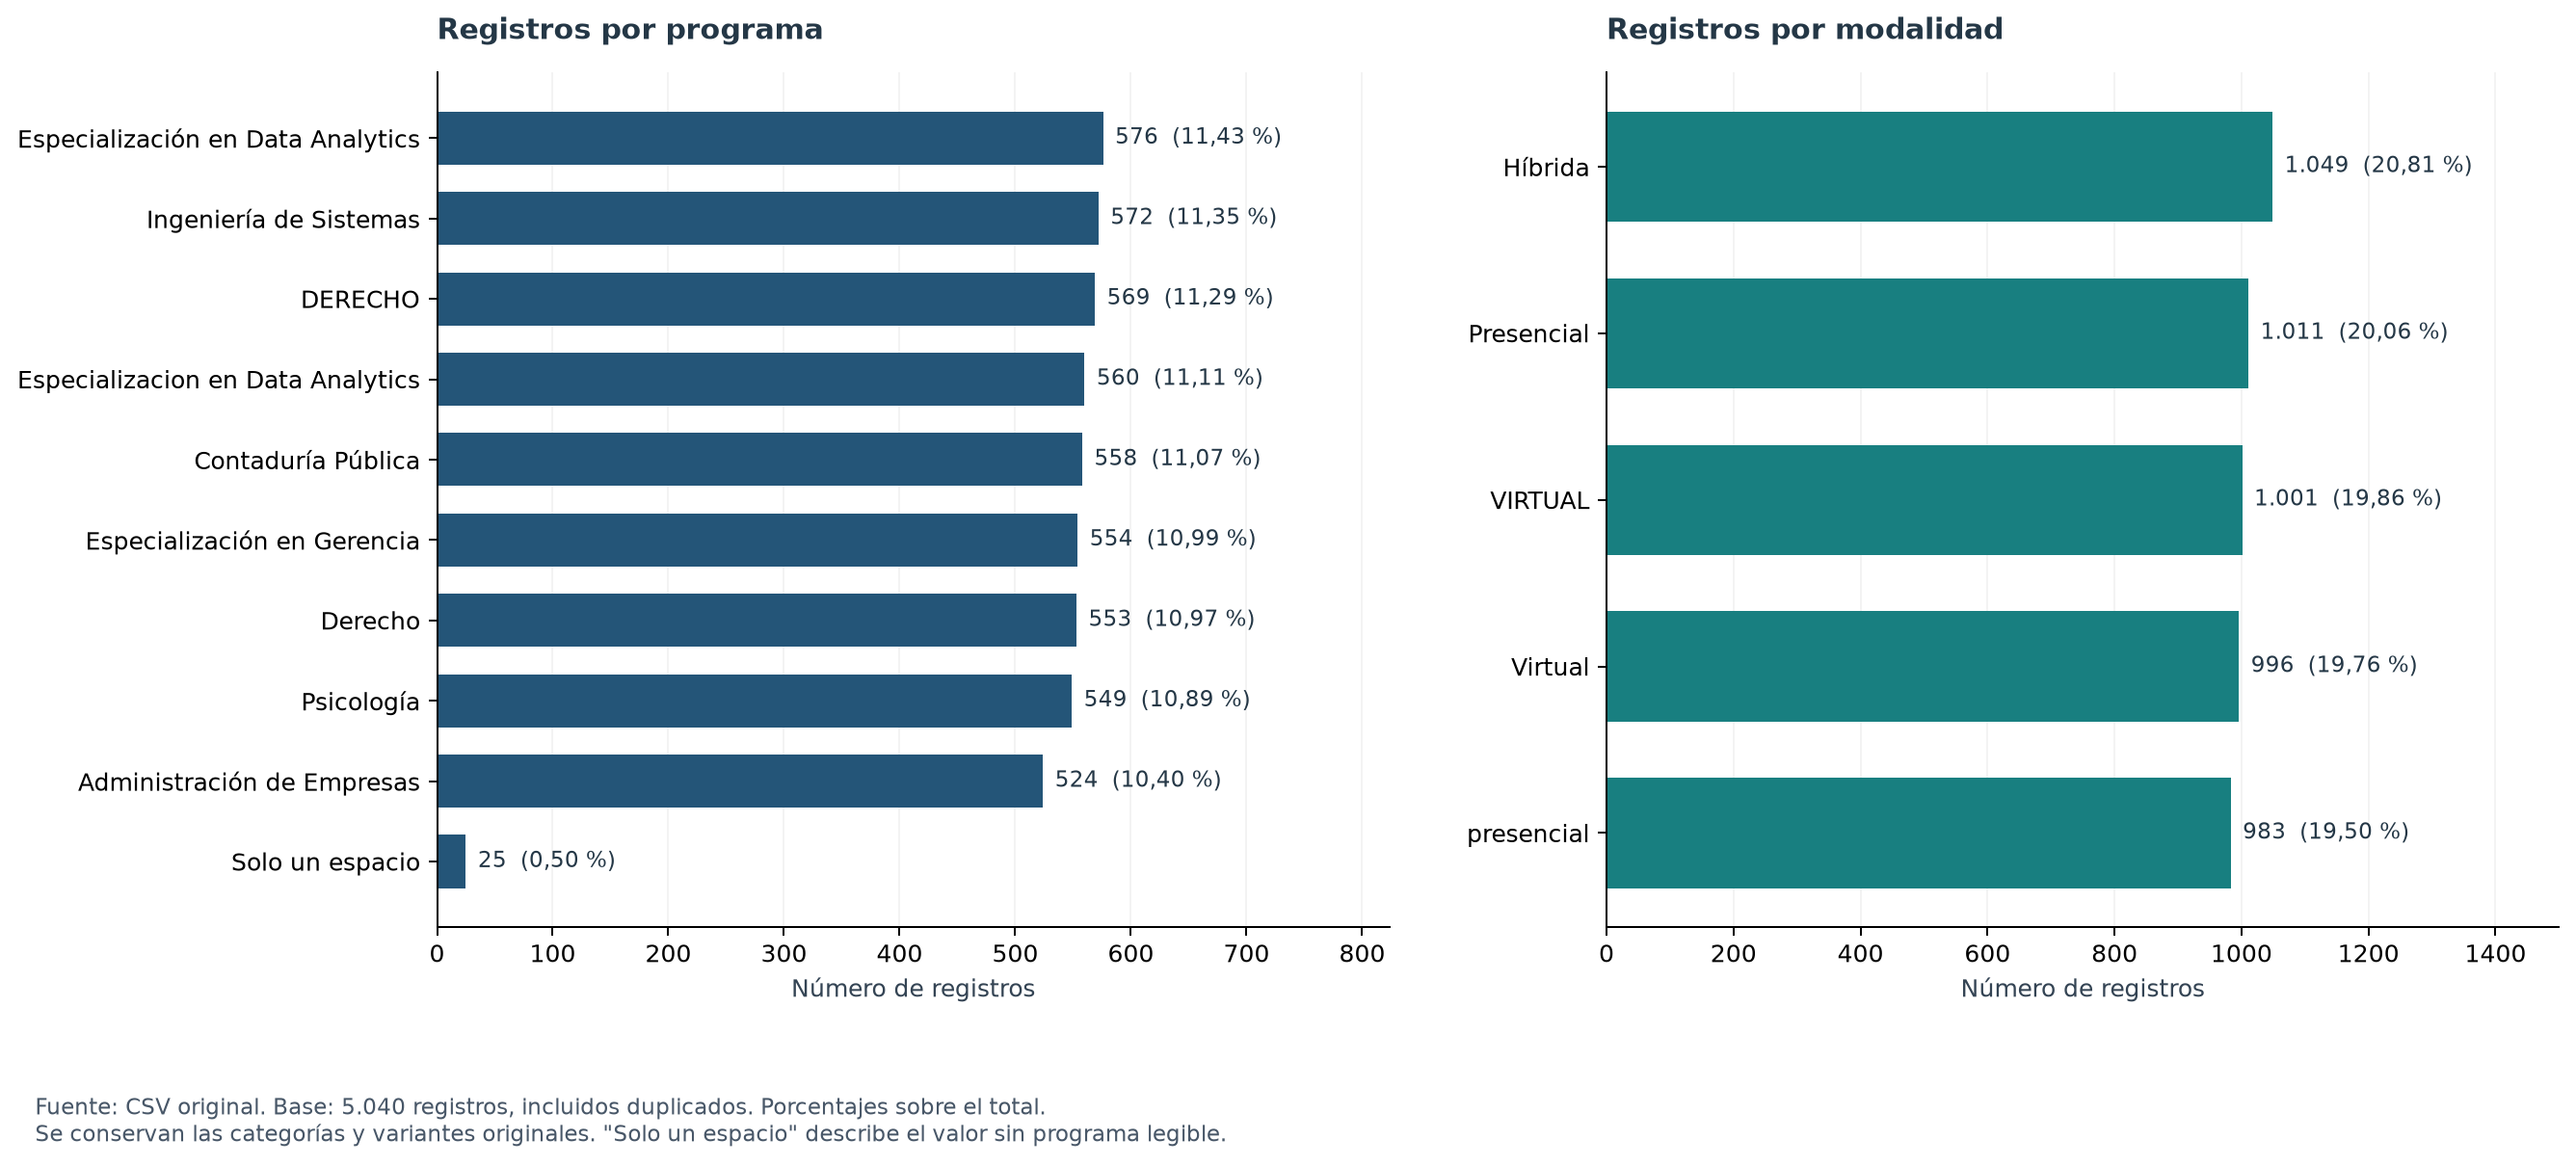

**Los canales tienen volúmenes próximos. Los paneles son distribuciones independientes, no un cruce ni una conversión.**

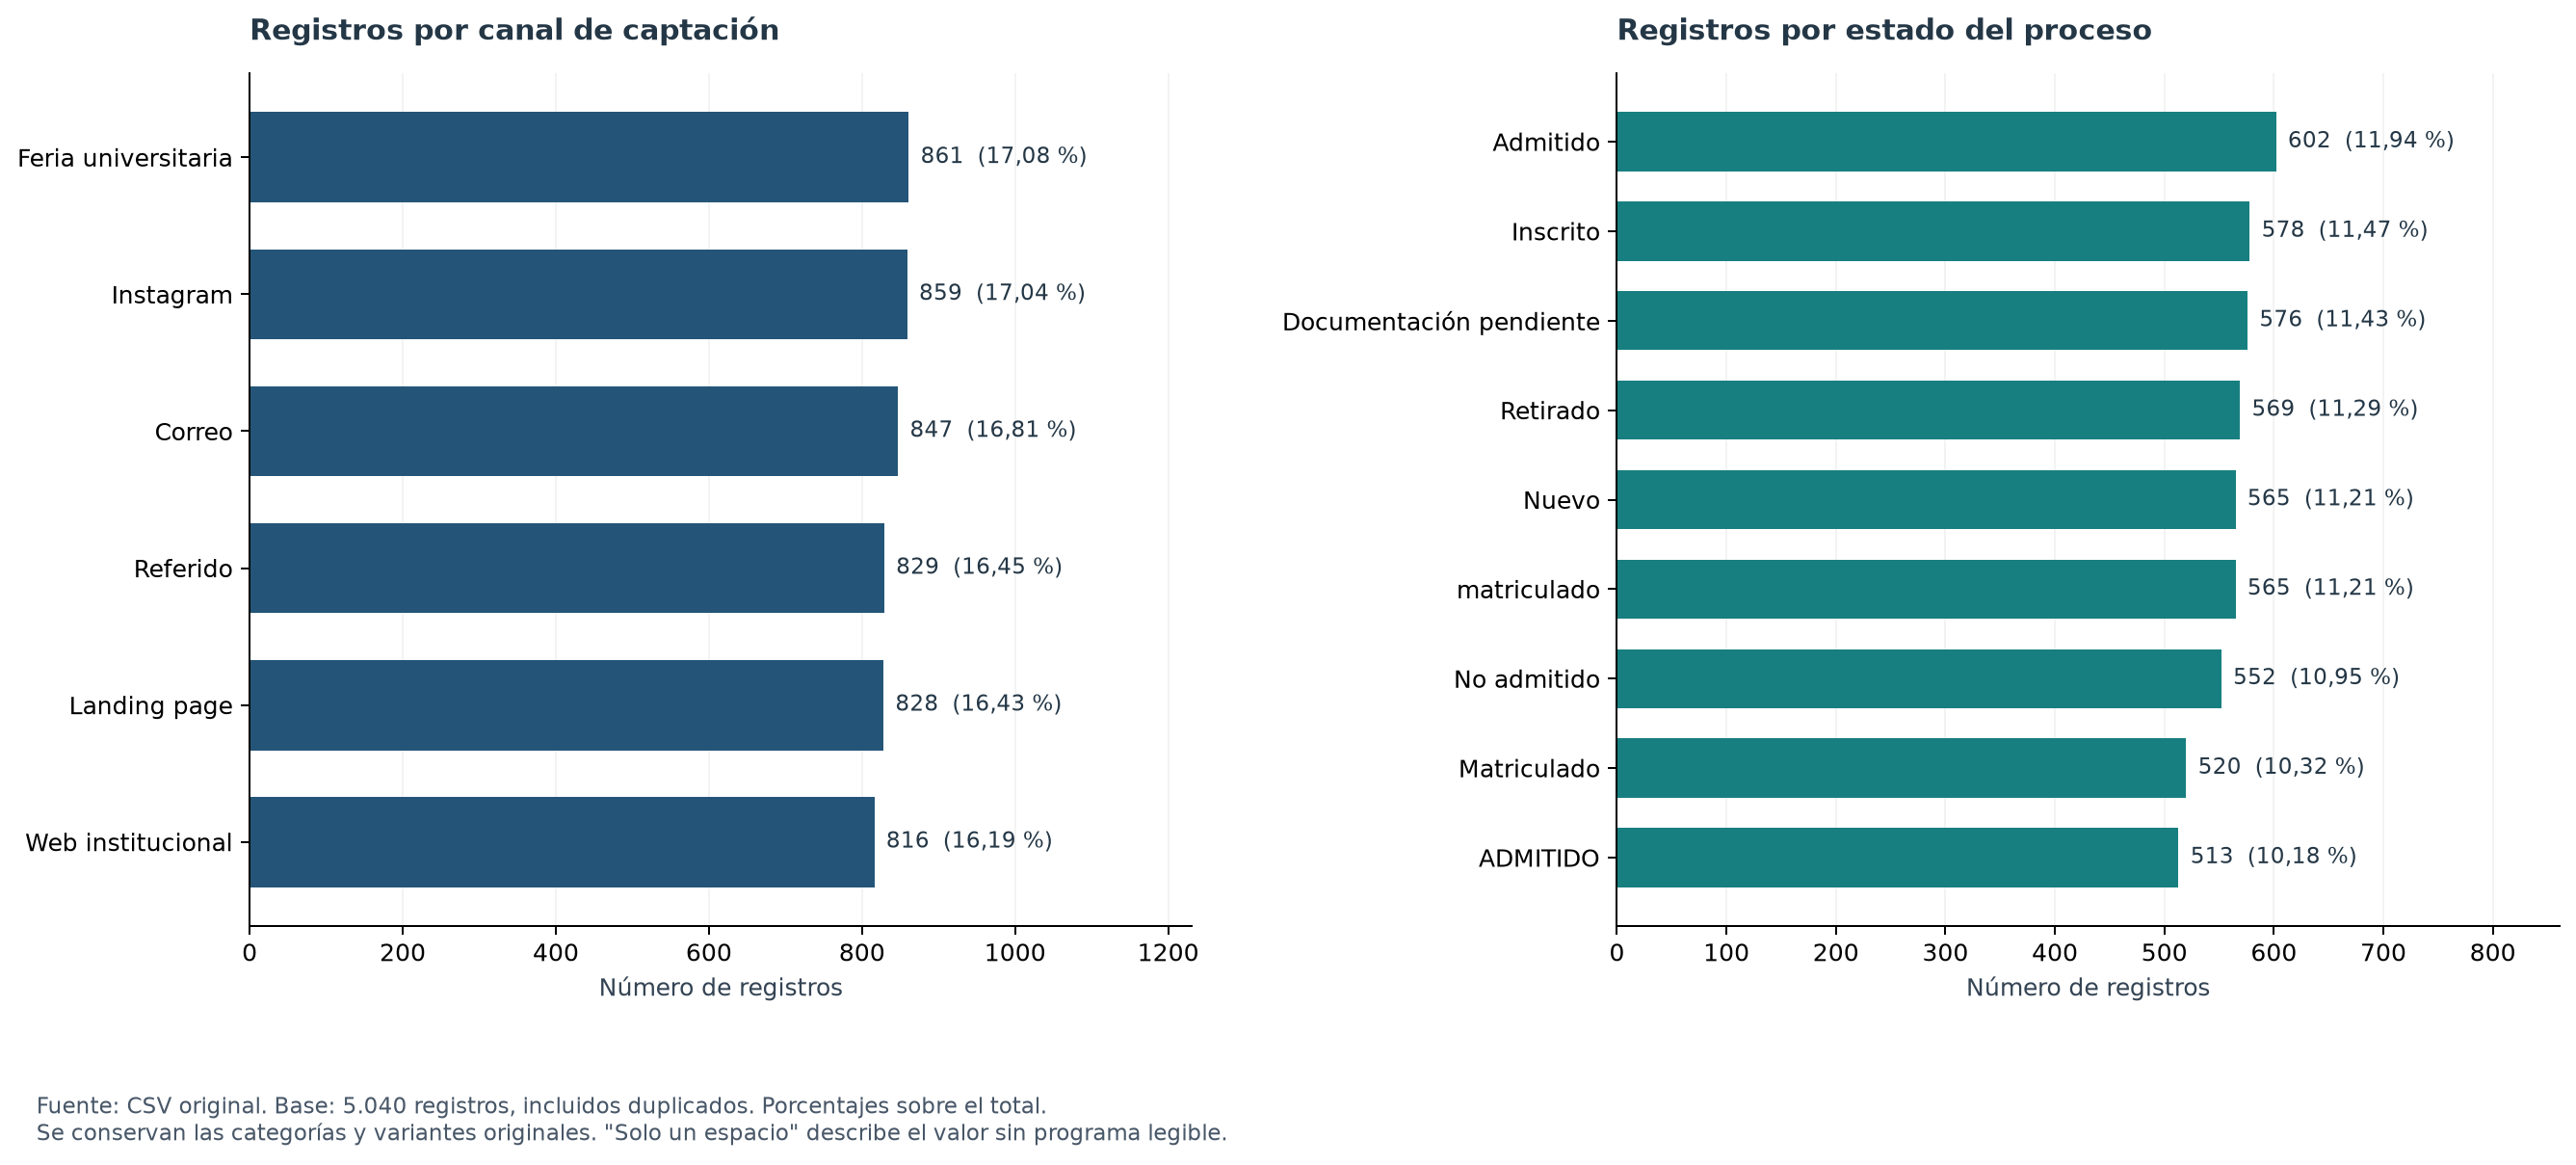

**Promedio 70,06 y mediana 70 sobre 4.811 puntajes. Sin atípicos según el criterio definido, sin certificar validez institucional.**

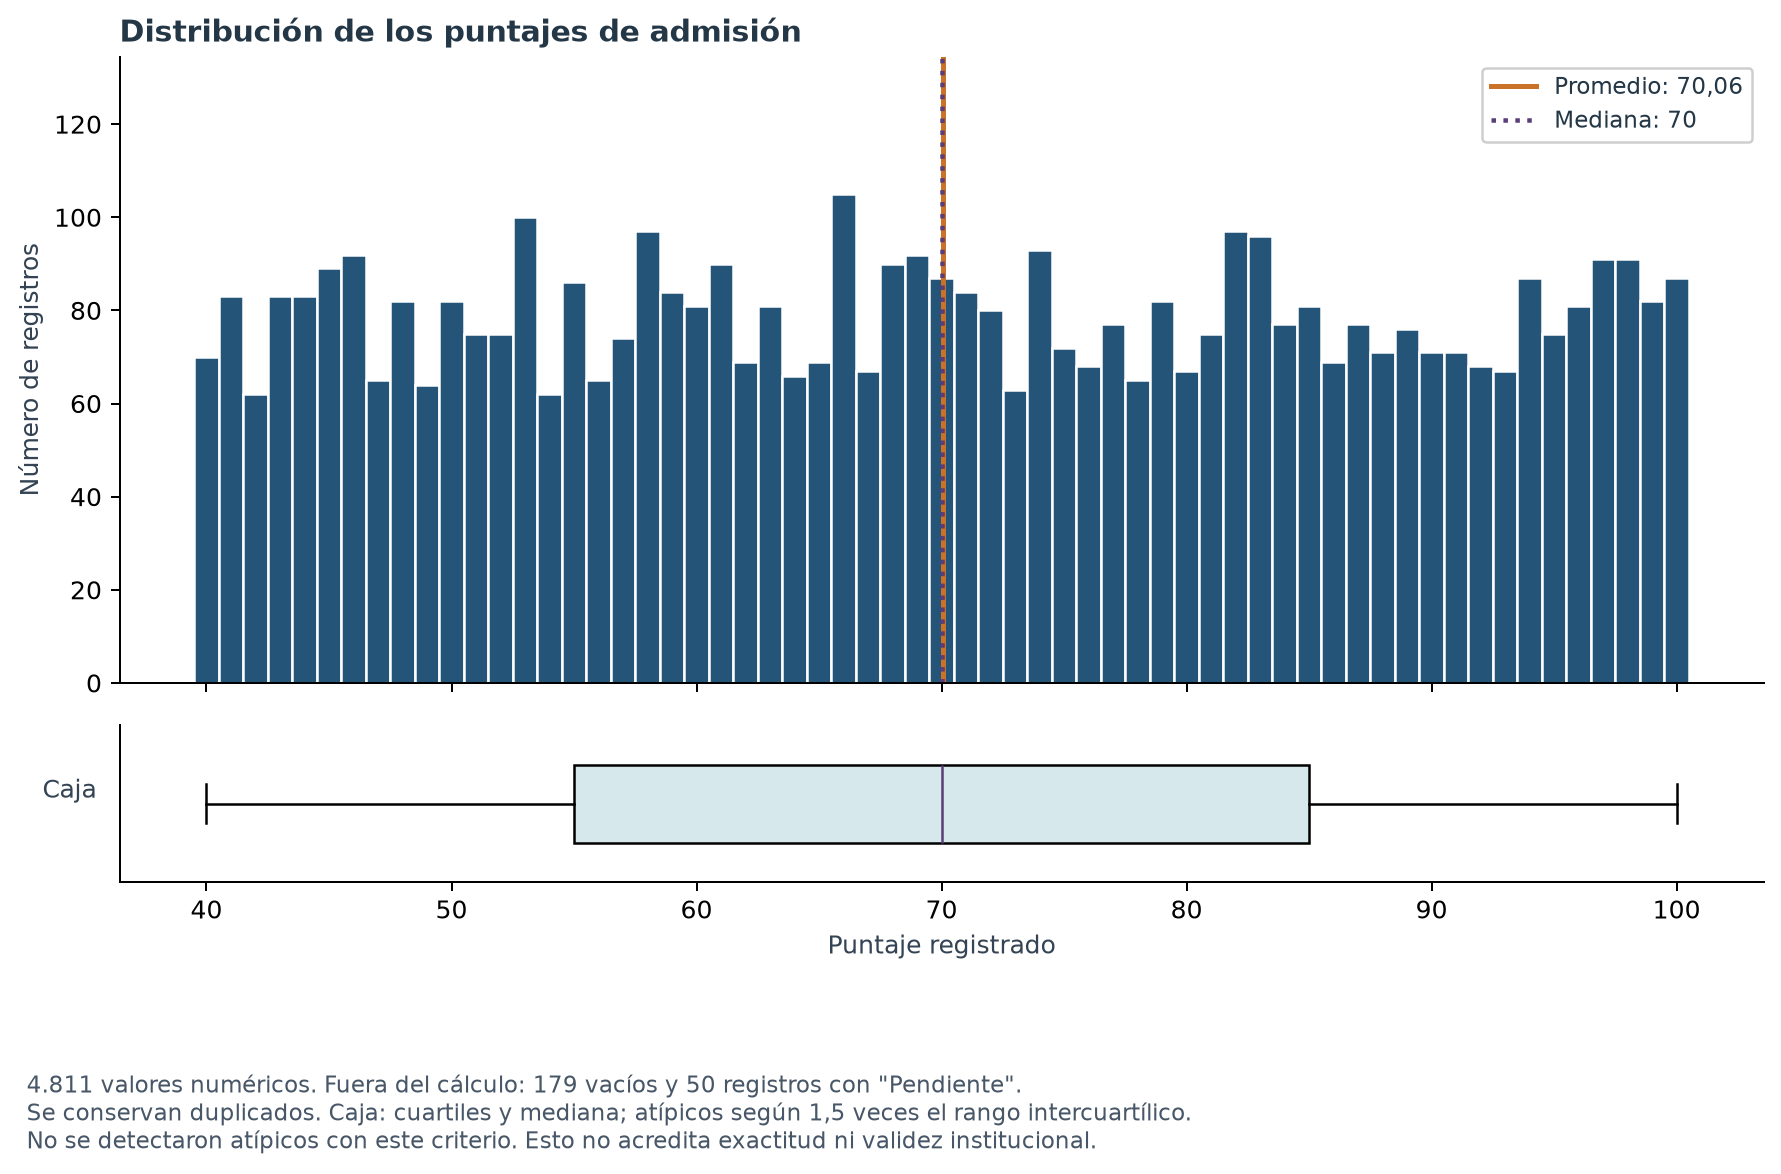

**Promedio aproximado de 2.611.605,65 COP y mediana de 2.500.000 COP sobre 4.179 valores. No son ingresos cobrados.**

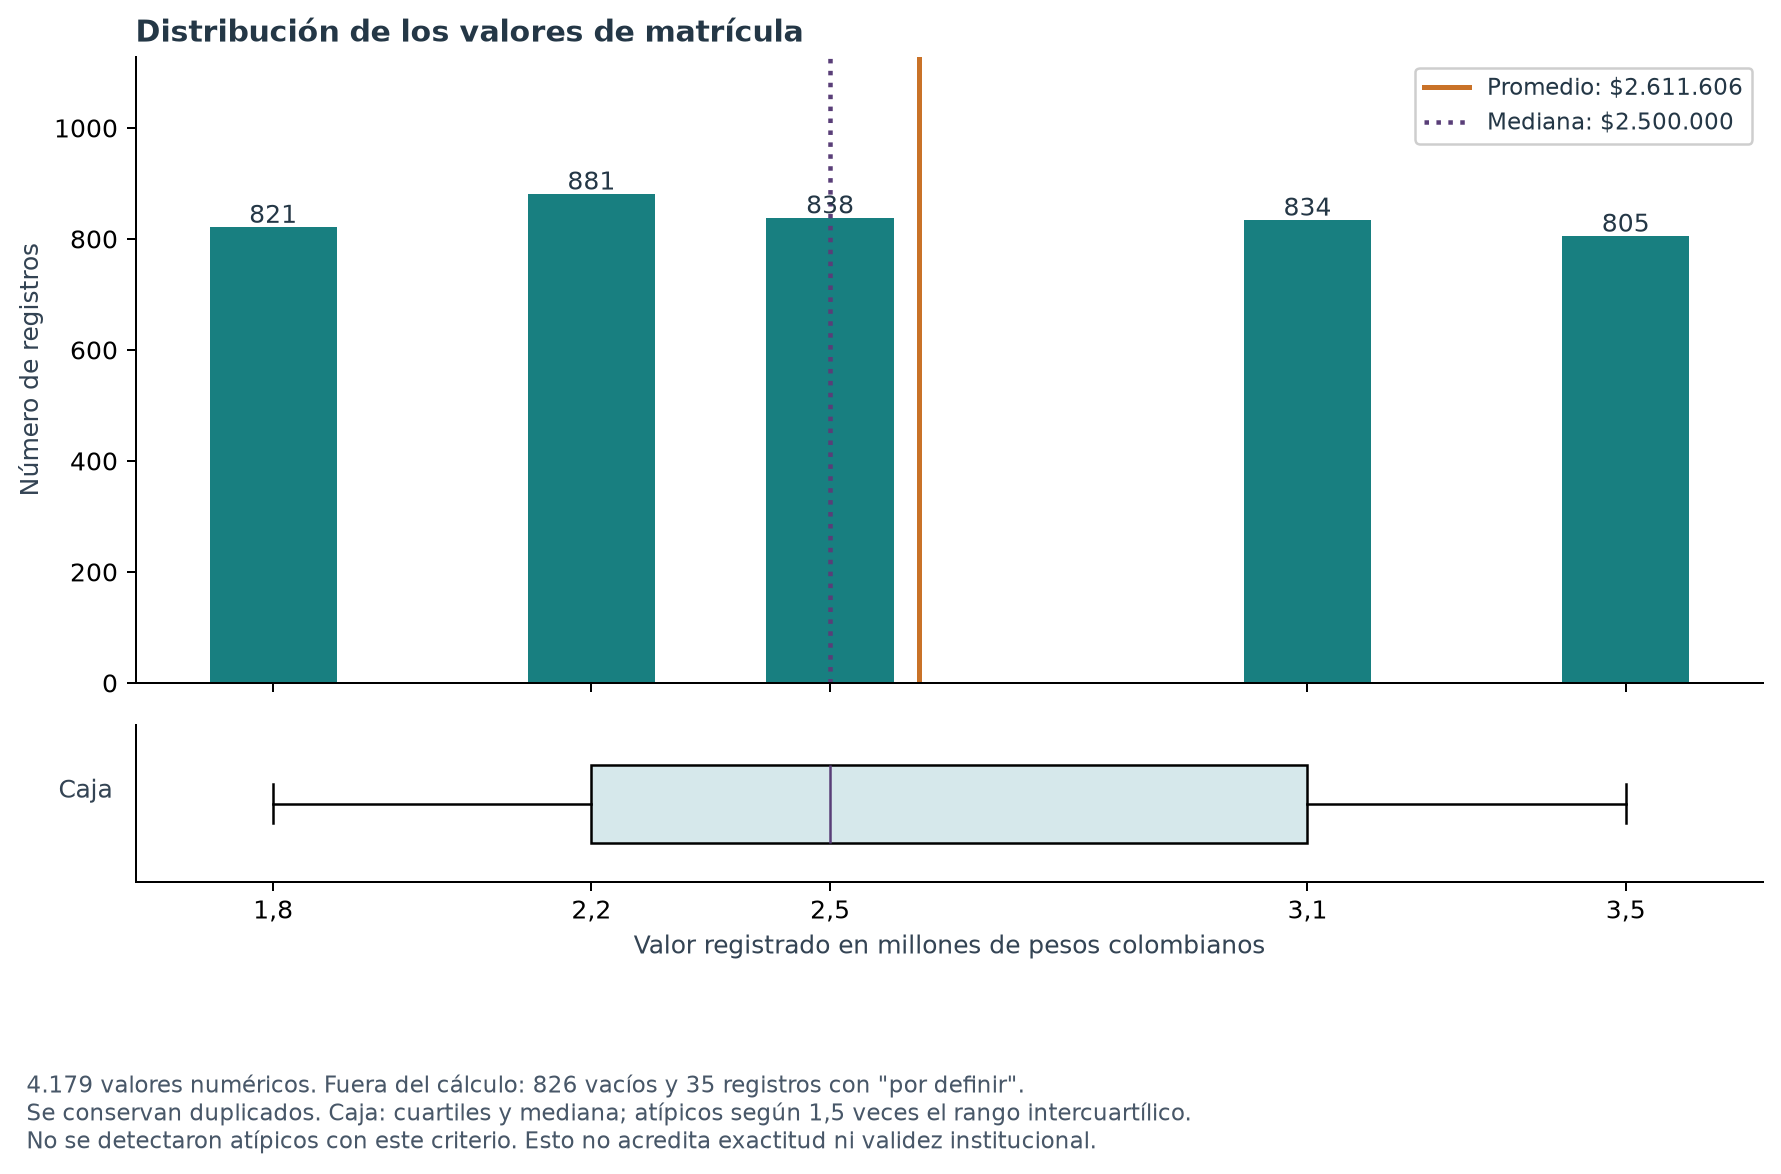

**Septiembre de 2026 tiene cobertura hasta el día 12; su menor cantidad no prueba una caída de demanda.**

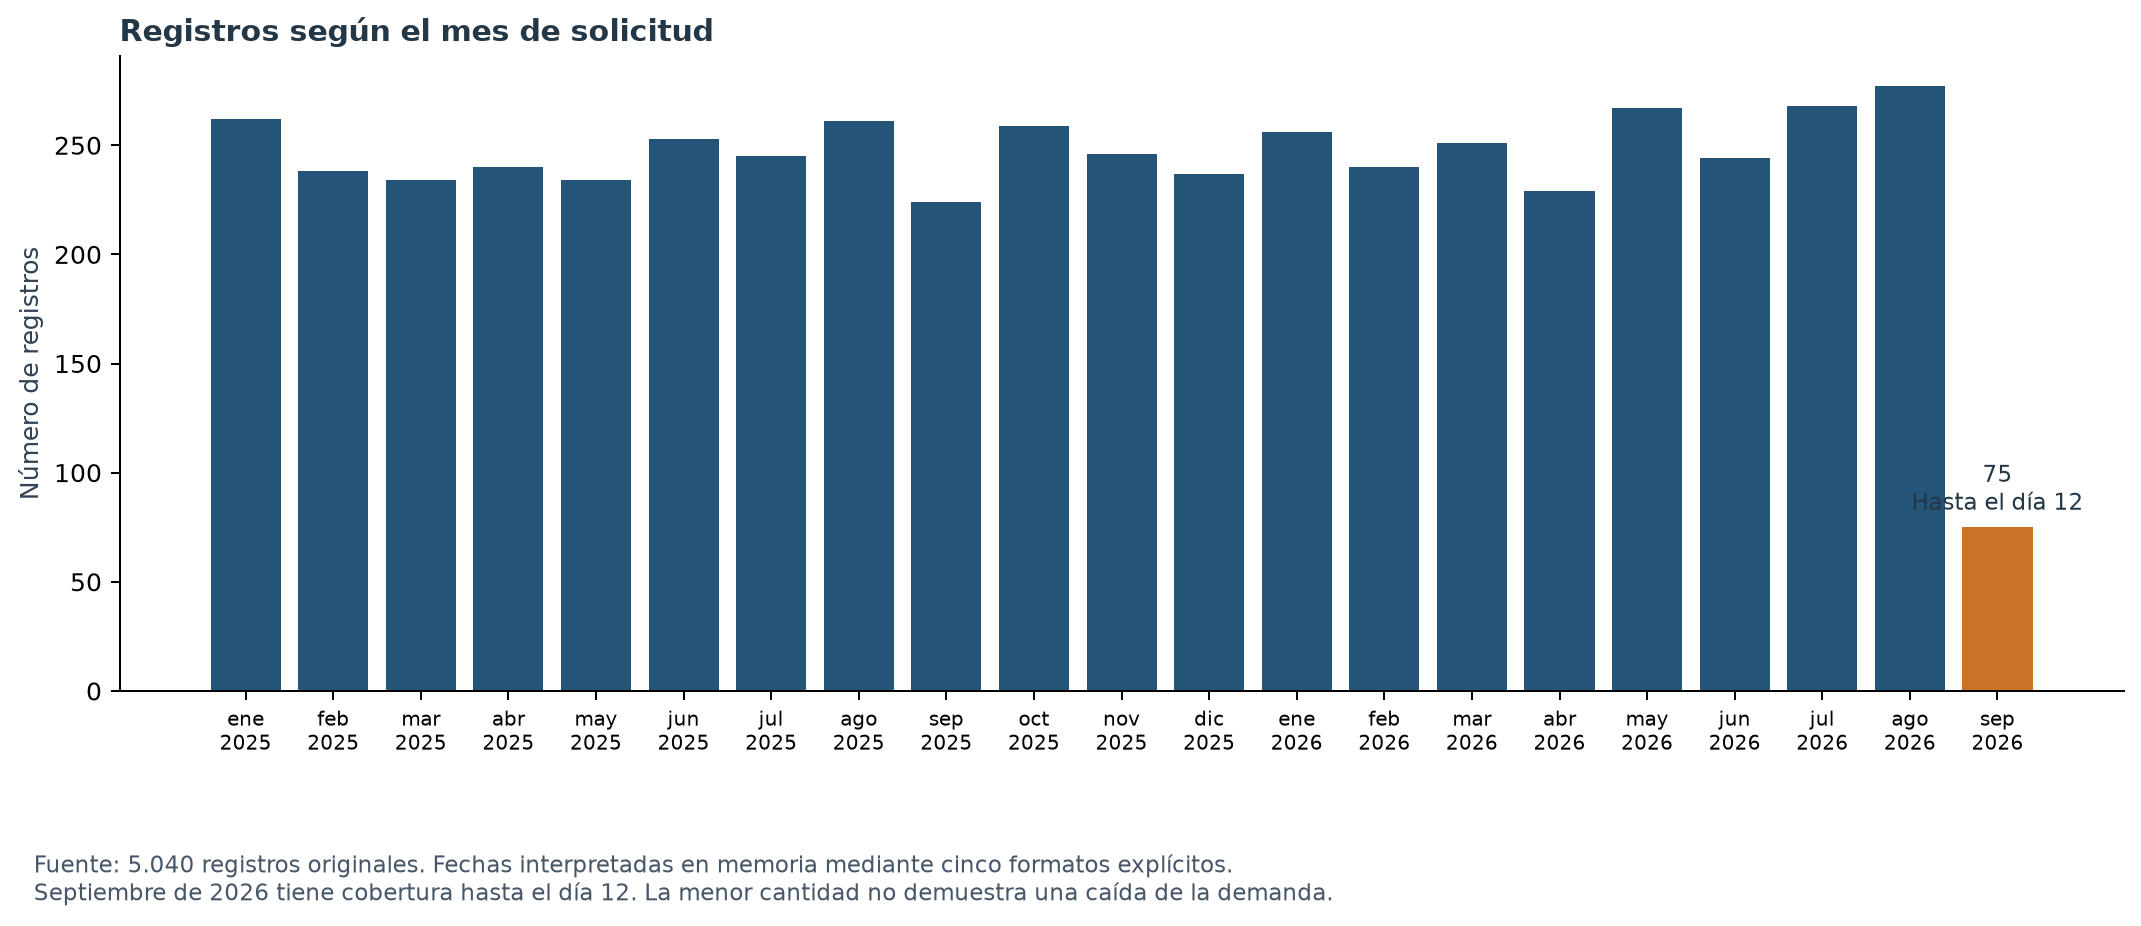

**Las ausencias deben interpretarse según el estado y la obligatoriedad; No aplica no se suma como vacío.**

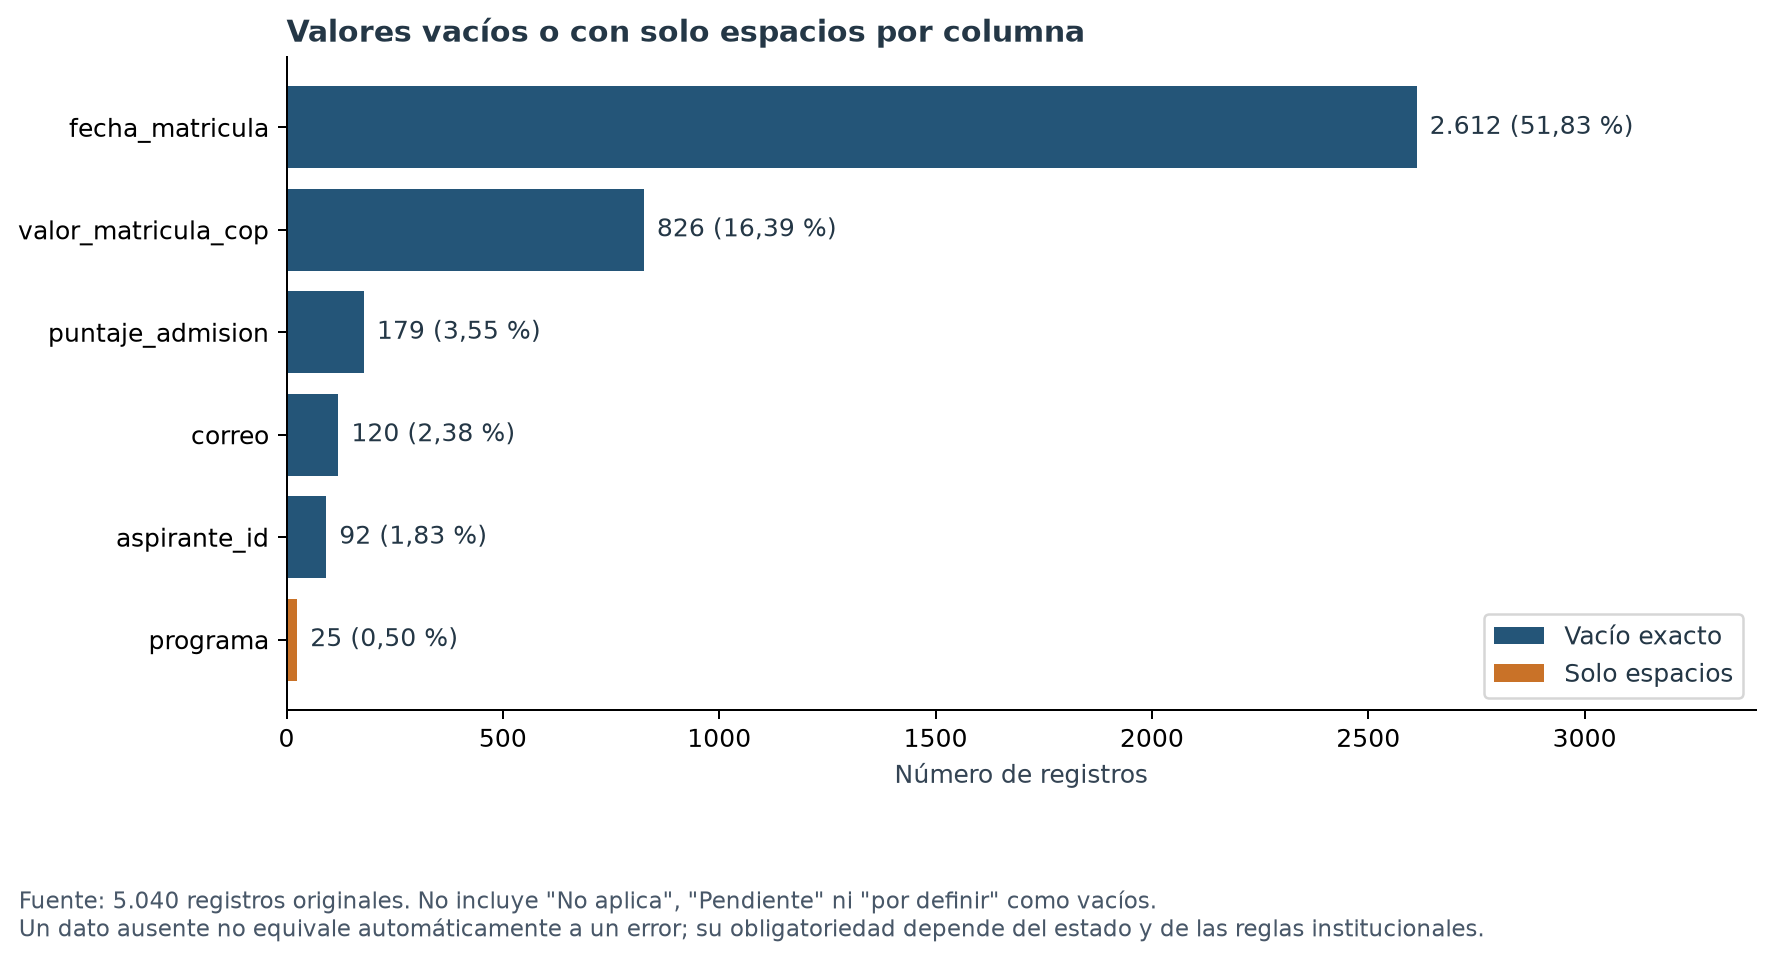

In [13]:
from analitica_admisiones.visualizations import main as generate_figures
generate_figures()
figure_notes = [
    ('01_programas_modalidades', 'La fragmentación por escritura impide concluir un ranking definitivo sin validar equivalencias.'),
    ('02_canales_estados', 'Los canales tienen volúmenes próximos. Los paneles son distribuciones independientes, no un cruce ni una conversión.'),
    ('03_distribucion_puntajes', 'Promedio 70,06 y mediana 70 sobre 4.811 puntajes. Sin atípicos según el criterio definido, sin certificar validez institucional.'),
    ('04_distribucion_matricula', 'Promedio aproximado de 2.611.605,65 COP y mediana de 2.500.000 COP sobre 4.179 valores. No son ingresos cobrados.'),
    ('05_cobertura_temporal', 'Septiembre de 2026 tiene cobertura hasta el día 12; su menor cantidad no prueba una caída de demanda.'),
    ('06_completitud', 'Las ausencias deben interpretarse según el estado y la obligatoriedad; No aplica no se suma como vacío.'),
]
for name, explanation in figure_notes:
    display(Markdown('**' + explanation + '**'))
    display(Image(filename=str(ROOT/'reports/figuras'/f'{name}.png'),width=1050))


## 7. Equivalencias propuestas, separadas del análisis original

Este bloque ilustra la propuesta del Anexo A para comprobar sus sumas. No es la base de las figuras
originales ni una limpieza ya aplicada. Se construye una copia temporal, se conservan todas las filas
y las equivalencias deben validarse institucionalmente. Sin programa registrado es una etiqueta de
presentación para un espacio, no una imputación. Los periodos se muestran aquí en el formato técnico original.


In [14]:
proposed = {
    'programa': {'DERECHO':'Derecho','Especializacion en Data Analytics':'Especialización en Data Analytics',' ':'Sin programa registrado'},
    'modalidad': {'VIRTUAL':'Virtual','presencial':'Presencial'},
    'estado_proceso': {'ADMITIDO':'Admitido','matriculado':'Matriculado'},
    'documentos_completos': {'sí':'Sí','SI':'Sí'},
    'ciudad_residencia': {'BOGOTA':'Bogotá','Cali ':'Cali','Popayan':'Popayán'},
    'asesor': {'asesor 1':'Asesor 1'},
    'periodo_academico': {'2026-I':'2026-1','2026 II':'2026-2'},
}
proposed_copy = df.copy(deep=True)
for column, mapping in proposed.items():
    proposed_copy[column] = proposed_copy[column].replace(mapping)
    table = proposed_copy[column].value_counts().rename_axis('Etiqueta propuesta').reset_index(name='Registros')
    table['Porcentaje del total'] = (100*table.Registros/N).round(2)
    display(Markdown('**Propuesta: '+column+'**'))
    display(table)
assert len(proposed_copy)==N
pd.testing.assert_frame_equal(df,original_df)


**Propuesta: programa**

,Etiqueta propuesta,Registros,Porcentaje del total
0,Especialización en Data Analytics,1136,22.54
1,Derecho,1122,22.26
2,Ingeniería de Sistemas,572,11.35
3,Contaduría Pública,558,11.07
4,Especialización en Gerencia,554,10.99
5,Psicología,549,10.89
6,Administración de Empresas,524,10.40
7,Sin programa registrado,25,0.50


**Propuesta: modalidad**

,Etiqueta propuesta,Registros,Porcentaje del total
0,Virtual,1997,39.62
1,Presencial,1994,39.56
2,Híbrida,1049,20.81


**Propuesta: estado_proceso**

,Etiqueta propuesta,Registros,Porcentaje del total
0,Admitido,1115,22.12
1,Matriculado,1085,21.53
2,Inscrito,578,11.47
3,Documentación pendiente,576,11.43
4,Retirado,569,11.29
5,Nuevo,565,11.21
6,No admitido,552,10.95


... (4 outputs left out)

**Propuesta: asesor**

,Etiqueta propuesta,Registros,Porcentaje del total
0,Asesor 1,2037,40.42
1,Sin asignar,1009,20.02
2,Asesor 2,998,19.80
3,Asesor 3,996,19.76


**Propuesta: periodo_academico**

,Etiqueta propuesta,Registros,Porcentaje del total
0,2026-1,2033,40.34
1,2026-2,2026,40.20
2,2025-2,981,19.46


## 8. Conciliación de cifras citadas

Cada afirmación cuantitativa se vincula con una salida anterior y un control. Los valores de 1.079
matriculados y 462 con documentación No o Pendiente corresponden a una base sin los duplicados exactos;
no deben mezclarse con los conteos originales de 1.085 y 465. Los conteos preliminares son registros.


In [15]:
checks = []
def check(name, observed, expected, section):
    checks.append({'Cifra o control':name,'Observado':str(observed),'Esperado':str(expected),
                   'Coincide':bool(observed==expected),'Respaldo':section})
check('Filas',N,5040,'Reconocimiento')
check('Columnas',len(headers),15,'Reconocimiento')
check('registro_id distintos',df.registro_id.nunique(),5000,'Reconocimiento')
check('aspirante_id distintos no vacíos',identified.aspirante_id.nunique(),2924,'Reconocimiento')
for col, empty in [('aspirante_id',92),('puntaje_admision',179),('valor_matricula_cop',826),('fecha_matricula',2612),('correo',120)]:
    check('Vacíos de '+col,int(df[col].eq('').sum()),empty,'Completitud')
check('Programa con solo espacios',int((df.programa.ne('') & df.programa.str.strip().eq('')).sum()),25,'Completitud')
check('Duplicados exactos adicionales',exact_extra,38,'Repeticiones')
check('Filas involucradas exactas',int(exact_involved.sum()),76,'Repeticiones')
check('Identificadores con discrepancias',partial_details.registro_id.nunique(),2,'Repeticiones')
check('Fechas solicitud formato alternativo',int((format_tables['fecha_solicitud'].query('`Formato o condición` != "Año mes día con guiones"')['Cantidad']).sum()),723,'Fechas')
check('Periodo 2025 segundo semestre y solicitud 2026',int(period_mismatch.sum()),410,'Fechas')
check('Septiembre de 2026',int(monthly.loc['2026/09']),75,'Cobertura temporal')
check('Matrícula No aplica',int(df.fecha_matricula.eq('No aplica').sum()),1343,'Fechas')
check('Matrículas posteriores a referencia',int(future.sum()),7,'Fechas; referencia no institucional')
check('Puntaje Pendiente',int(df.puntaje_admision.eq('Pendiente').sum()),50,'Numéricas')
check('Valor por definir',int(df.valor_matricula_cop.eq('por definir').sum()),35,'Numéricas')
for column,expected_n,expected_mean,expected_median in [('puntaje_admision',4811,70.05549781750156,70),('valor_matricula_cop',4179,2611605.647284039,2500000)]:
    record=numeric_table.set_index('Columna').loc[column]
    check('Cantidad numérica '+column,int(record['Valores utilizados']),expected_n,'Numéricas')
    check('Promedio '+column,bool(np.isclose(record.Promedio,expected_mean)),True,'Numéricas')
    check('Mediana '+column,float(record.Mediana),expected_median,'Numéricas')
    check('Negativos '+column,int(record.Negativos),0,'Numéricas')
    check('Atípicos según criterio '+column,int(record['Atípicos según criterio']),0,'Numéricas')
check('Matriculados dos etiquetas',int(matriculated.sum()),1085,'Cruces explícitos')
check('Matriculados con No o Pendiente',int((matriculated & without_docs).sum()),465,'Cruces explícitos')
check('Documentación afirmativa tres etiquetas',int(df.documentos_completos.isin(['Sí','sí','SI']).sum()),3023,'Cruces explícitos')
check('Datos numéricos y textos siguen intactos',df.equals(original_df),True,'Integridad')
validation=pd.DataFrame(checks)
display(validation)
assert validation.Coincide.all(), 'Hay diferencias respecto a cifras del informe'


,Cifra o control,Observado,Esperado,Coincide,Respaldo
0,Filas,5040,5040,True,Reconocimiento
1,Columnas,15,15,True,Reconocimiento
2,registro_id distintos,5000,5000,True,Reconocimiento
3,aspirante_id distintos no vacíos,2924,2924,True,Reconocimiento
4,Vacíos de aspirante_id,92,92,True,Completitud
5,Vacíos de puntaje_admision,179,179,True,Completitud
6,Vacíos de valor_matricula_cop,826,826,True,Completitud
7,Vacíos de fecha_matricula,2612,2612,True,Completitud
8,Vacíos de correo,120,120,True,Completitud
9,Programa con solo espacios,25,25,True,Completitud


## 9. Cinco hallazgos y alcance

1. Se encontraron 38 pares de filas idénticas y dos identificadores con discrepancias. No permiten interpretar las 5.040 filas como solicitudes únicas.
2. Las variantes de programas, modalidades y estados fragmentan los conteos. Sus equivalencias son propuestas pendientes de validación.
3. Los canales representan entre 16,19 % y 17,08 % de las filas. No son tasas de efectividad o conversión.
4. Puntajes e importes no presentan atípicos bajo el criterio definido. La ausencia de extremos no valida reglas institucionales ni acredita pagos.
5. Septiembre de 2026 reúne 75 registros hasta el día 12. La cobertura parcial impide interpretar el menor volumen como caída de la demanda.

### Preguntas e hipótesis pendientes

**Demanda por programa.** Las participaciones pueden cambiar al validar claves y equivalencias, sin que
se pueda anticipar su dirección. ¿Cuántas solicitudes y aspirantes únicos existen por programa y periodo,
y qué proporción de las solicitudes llega a matrícula efectiva con una ventana de seguimiento definida?

**Canales.** Las diferencias preliminares pueden estar relacionadas con la composición de programas,
modalidades y periodos. ¿Se mantienen al comparar grupos equivalentes y solicitudes únicas?

**Documentación y asesor.** La documentación incompleta y la falta de asignación podrían estar asociadas
con la distribución de estados. ¿Cómo varía esa distribución al comparar un mismo programa, modalidad y periodo?

Las hipótesis no se validan por el mero hecho de limpiar. Para conocer permanencia en documentación
pendiente o secuencia hasta el retiro se requiere un historial de cambios de estado y asignaciones.
Exactitud requiere contraste con fuentes reales; oportunidad requiere metadatos de actualización.


In [16]:
# Exportaciones de evidencia del mismo recorrido, sin sobrescribir el origen.
export = ROOT/'reports/respaldo_notebook'
export.mkdir(parents=True,exist_ok=True)
quality.to_csv(export/'calidad_por_columna.csv',index=False)
exact_details.to_csv(export/'duplicados_exactos.csv',index=False)
partial_details.to_csv(export/'discrepancias_por_identificador.csv',index=False)
numeric_table.to_csv(export/'estadisticas_numericas.csv',index=False)
channel_state.to_csv(export/'canal_estado_cantidades.csv')
channel_state_pct.to_csv(export/'canal_estado_porcentajes_dentro_canal.csv')
validation.to_csv(export/'conciliacion_cifras_informe.csv',index=False)
for column,table in frequencies.items():
    table.to_csv(export/f'frecuencias_{column}.csv',index=False)
assert hashlib.sha256(source.read_bytes()).hexdigest()==original_hash
pd.testing.assert_frame_equal(df,original_df)
print(f'FINALIZADO: {len(validation)} verificaciones correctas. Original intacto: {N} filas y {len(headers)} columnas.')
print('Evidencias exportadas en:',export.relative_to(ROOT))


FINALIZADO: 34 verificaciones correctas. Original intacto: 5040 filas y 15 columnas.
Evidencias exportadas en: reports/respaldo_notebook
